# Model MS-AR a strategia inwestycyjna na akcjach CD Projekt

Notebook jest sterownikiem: wczytuje dane, wywołuje funkcje z `src/` i zapisuje wyniki
do `outputs/`. Logika liczbowa nie mieszka w komórkach.

Pełny przebieg trwa około minuty; kosztowna jest wyłącznie pętla rozszerzającego się
okna, która estymuje model 153 razy.

In [1]:
import sys
from pathlib import Path

# Korzen projektu szukany w gore od katalogu roboczego. Edytory oparte na VS Code
# ustawiaja katalog roboczy notebooka roznie, wiec rozpoznawanie po nazwie zawodzi.
PROJECT_ROOT = Path.cwd().resolve()
while not (PROJECT_ROOT / 'src' / 'config.py').is_file():
    if PROJECT_ROOT == PROJECT_ROOT.parent:
        raise RuntimeError(f'Nie znaleziono korzenia projektu startujac z {Path.cwd()}.')
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT))
print('PROJECT_ROOT:', PROJECT_ROOT)

PROJECT_ROOT: D:\studia\ZEII\ms-ar-cdprojekt


In [2]:
from src import backtest, config, data_load, regimes, viz

SAVE = True  # zapis rysunkow i tabel do outputs/
config.ensure_output_dirs()

## Dane i próba

In [3]:
daily = data_load.load_daily_prices()
weekly = data_load.to_weekly(daily)
r_weekly = data_load.weekly_log_returns(weekly)
r_daily = data_load.daily_log_returns(daily)
start_idx = data_load.split_point(r_weekly)

for key, value in data_load.sample_description(daily, r_weekly).items():
    print(f'{key}: {value}')

obserwacje_dzienne: 2733
pierwsza_obserwacja: 2015-01-02
ostatnia_obserwacja: 2025-12-03
tygodnie_treningowe: 416
tygodnie_testowe: 153


Agregacja do tygodni wygładza wahania płynności, które nie niosą informacji o kondycji
spółki, i wyostrza różnicę wariancji między reżimami.

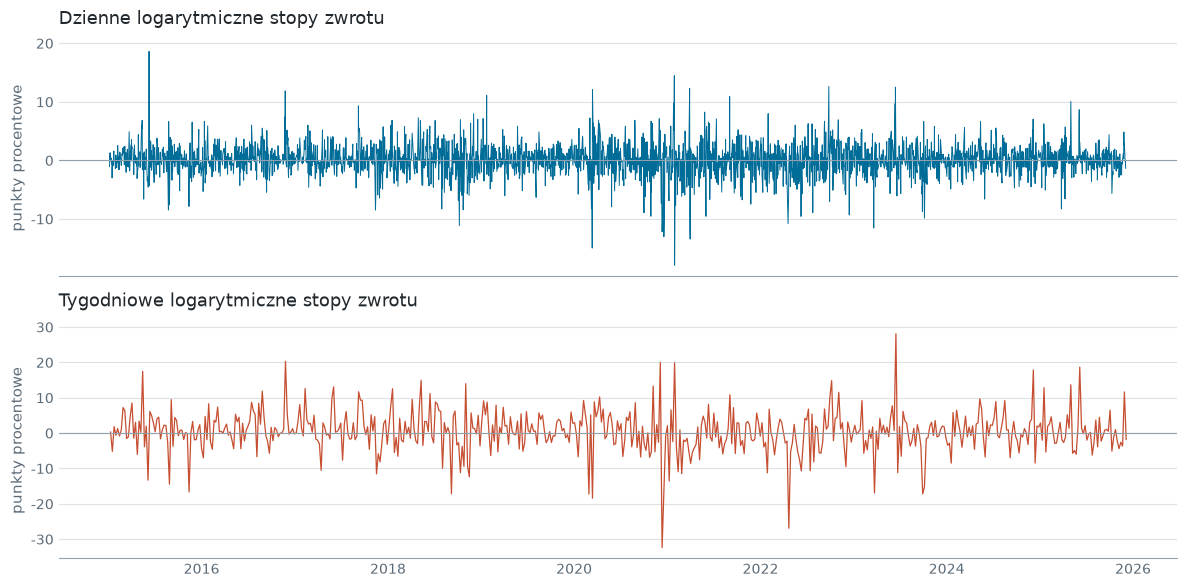

In [4]:
viz.plot_frequency_comparison(r_daily, r_weekly, save=SAVE);

## Stacjonarność

In [5]:
adf = data_load.adf_table(weekly)
if SAVE:
    adf.to_csv(config.TABLES / 'test_adf.csv', float_format='%.3f', encoding='utf-8')
print(adf.to_string(float_format=lambda x: f'{x:.3f}'))

                                          Statystyka testowa  P-value
Szereg                                                               
Logarytm cen akcji                                    -2.373    0.150
Logarytmowane pierwsze roznice cen akcji             -14.577    0.000


## Reżimy zmienności na próbie treningowej

In [6]:
history = regimes.fit_ms_ar(
    r_weekly.loc[:config.SIMULATION_START].iloc[:-1], config.SEARCH_REPS_HISTORY
)
history_regimes = regimes.regime_variances(history)
print(f"wariancja rezimu niskiej zmiennosci:  {history_regimes['low_var']:.2f}")
print(f"wariancja rezimu wysokiej zmiennosci: {history_regimes['high_var']:.2f}")

wariancja rezimu niskiej zmiennosci:  14.32
wariancja rezimu wysokiej zmiennosci: 91.48


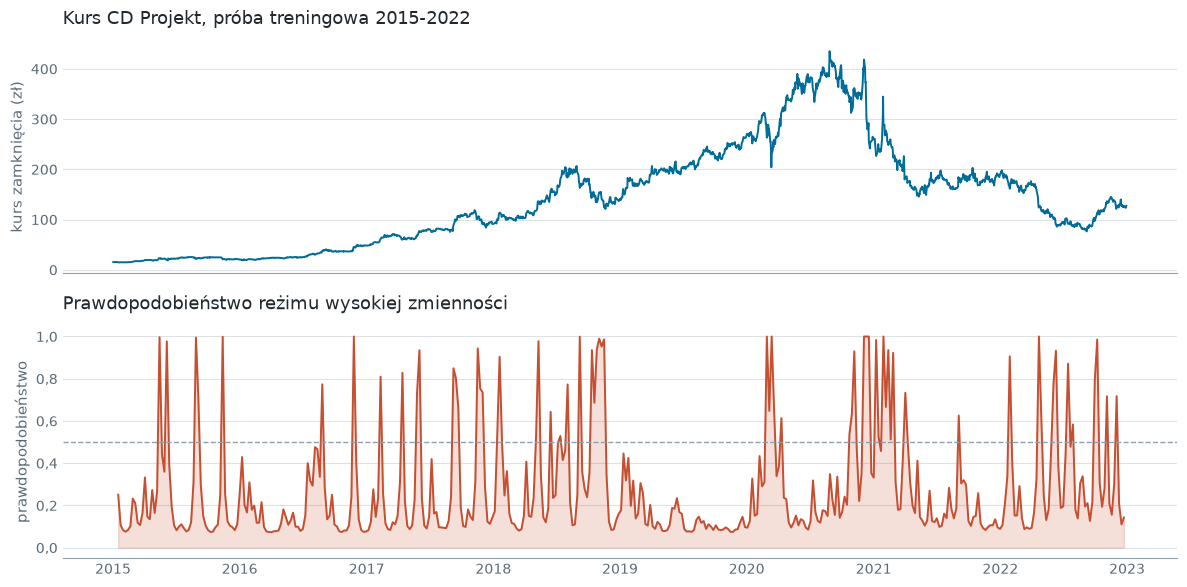

In [7]:
train_prices = daily.loc[: config.SIMULATION_START, 'Zamkniecie']
viz.plot_regimes(
    train_prices,
    regimes.smoothed_high_vol(history, history_regimes),
    title='Kurs CD Projekt, próba treningowa 2015-2022',
    name='02_rezimy_proba_treningowa.png',
    save=SAVE,
);

## Procedura rozszerzającego się okna

W każdym kroku model estymowany jest wyłącznie na danych dostępnych do tego tygodnia,
a decyzja opiera się na prawdopodobieństwie filtrowanym. Prawdopodobieństwa wygładzone
korzystają z całej próby, więc w symulacji decyzyjnej wprowadziłyby informację
z przyszłości.

Ta komórka liczy się najdłużej, około minuty.

In [8]:
signals, last_model = regimes.walk_forward_signals(r_weekly, start_idx)
last_regimes = regimes.regime_variances(last_model)
transitions = regimes.transition_matrix(last_model, last_regimes)

if SAVE:
    signals.to_csv(config.TABLES / 'sygnaly_walk_forward.csv', encoding='utf-8')
    transitions.to_csv(config.TABLES / 'macierz_przejscia.csv',
                       float_format='%.4f', encoding='utf-8')

print(f"wariancja niska:  {last_regimes['low_var']:.2f}")
print(f"wariancja wysoka: {last_regimes['high_var']:.2f}")
print()
print(transitions.to_string(float_format=lambda x: f'{x:.2%}'))
print()
print(f'udzial tygodni w stanie wysokiego ryzyka: {regimes.high_risk_share(signals):.2%}')

wariancja niska:  11.60
wariancja wysoka: 88.30

                     Do: niska zmiennosc  Do: wysoka zmiennosc
Z: niska zmiennosc                79.48%                20.52%
Z: wysoka zmiennosc               48.41%                51.59%

udzial tygodni w stanie wysokiego ryzyka: 9.15%


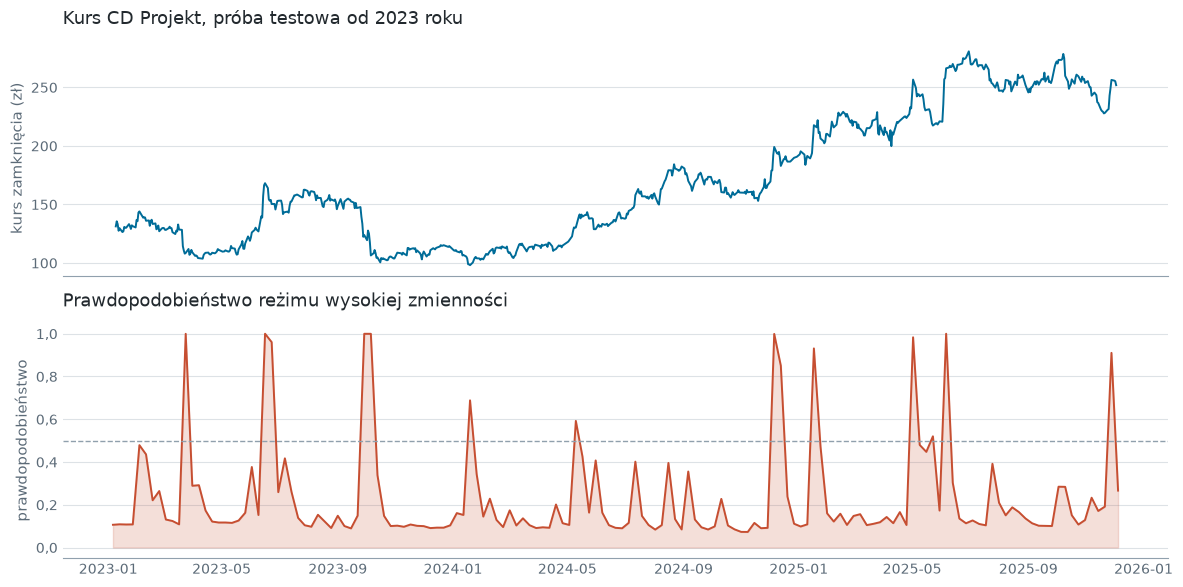

In [9]:
test_prices = daily.loc[signals.index[0]:signals.index[-1], 'Zamkniecie']
viz.plot_regimes(
    test_prices,
    1.0 - signals['prob_low_vol'],
    title='Kurs CD Projekt, próba testowa od 2023 roku',
    name='03_rezimy_proba_testowa.png',
    save=SAVE,
);

## Symulacja strategii

In [10]:
result = backtest.simulate(daily, signals)
if SAVE:
    backtest.save_log(result['log'])

for key, value in result['summary'].items():
    print(f'{key}: {value:,.2f}' if isinstance(value, float) else f'{key}: {value}')

kapital_poczatkowy: 10,000.00
prowizja: 0.00
kapital_koncowy_strategia: 26,147.30
kapital_koncowy_benchmark: 19,782.00
stopa_zwrotu_strategia: 161.47
stopa_zwrotu_benchmark: 97.82
liczba_transakcji: 22


In [11]:
print(result['log'].to_string(float_format=lambda x: f'{x:,.2f}'))

                 Operacja   Cena  Wolumen  Prowizja     Saldo  Benchmark  Wartosc strategii  Roznica
Data transakcji                                                                                     
2023-01-10            KUP 129.81    77.03      0.00      0.00  10,000.00          10,000.00     0.00
2023-03-27       SPRZEDAJ 109.44     0.00      0.00  8,430.30   8,430.30           8,430.30     0.00
2023-04-03            KUP 108.89    77.42      0.00      0.00   8,387.94           8,430.30    42.37
2023-06-19       SPRZEDAJ 167.17     0.00      0.00 12,942.45  12,877.40          12,942.45    65.04
2023-07-03            KUP 153.32    84.41      0.00      0.00  11,810.65          12,942.45 1,131.79
2023-10-02       SPRZEDAJ 124.93     0.00      0.00 10,546.00   9,623.77          10,546.00   922.23
2023-10-16            KUP 106.83    98.72      0.00      0.00   8,229.40          10,546.00 2,316.60
2024-01-22       SPRZEDAJ  98.97     0.00      0.00  9,769.65   7,623.59           9,769.65

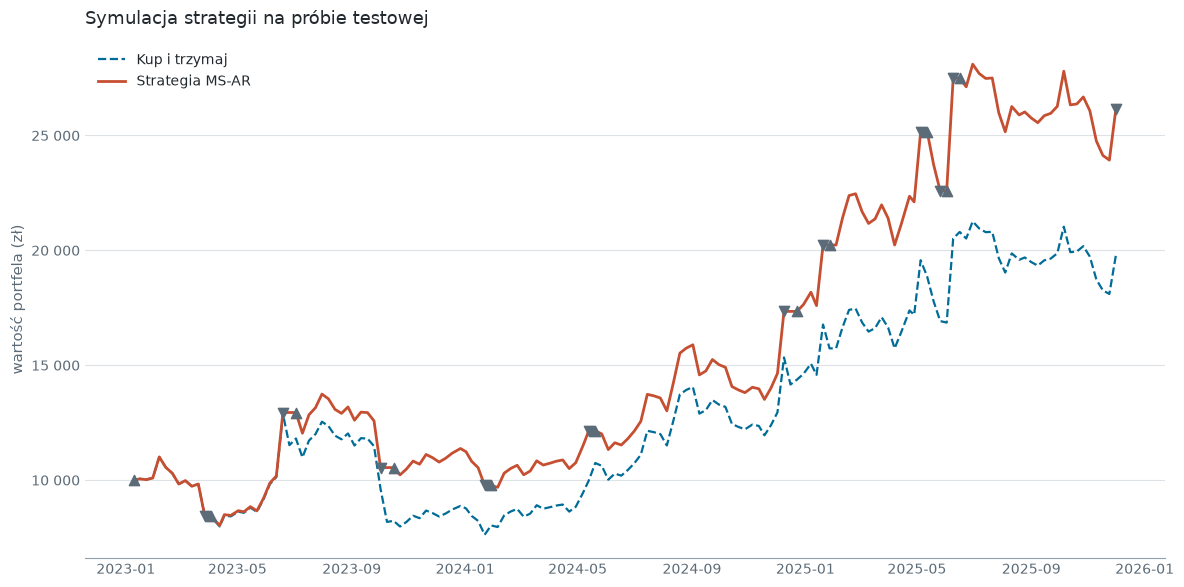

In [12]:
viz.plot_strategy(result['equity'], result['benchmark'], result['log'], save=SAVE);